In [5]:
import numpy as np
import pandas as pd
import os
import tensorflow as tf
import tensorflow.keras.layers as layers
import matplotlib.pyplot as plt
import itertools

#Import image read library
from PIL import Image
# Install torchcam
!pip install torchcam -q

# Now import
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask

#Import ML library
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score , confusion_matrix

In [6]:
# Add these imports for GradCAM
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

In [7]:
DATASET_PATH = "/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset"

In [8]:
import pathlib
data_dir = '/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset'
data_dir = pathlib.Path(data_dir).with_suffix('')

In [10]:
def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.2,
    subset='training',
    seed = 123,
    label_mode = 'categorical',
    batch_size=32,
    image_size=(256,256)
)
validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split = 0.3,
    subset='validation',
    seed = 123,
    label_mode = 'categorical',
    batch_size=32,
    image_size=(256,256)
)
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

Found 17092 files belonging to 8 classes.
Using 13674 files for training.
Found 17092 files belonging to 8 classes.
Using 5127 files for validation.


In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

In [12]:
DATASET_PATH = Path("/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset")

In [13]:
basophil = list((DATASET_PATH/"basophil").glob("*"))
eosinophil = list((DATASET_PATH/"eosinophil").glob("*"))
erythroblast = list((DATASET_PATH/"erythroblast").glob("*"))
ig = list((DATASET_PATH/"ig").glob("*"))
lymphocyte = list((DATASET_PATH/"lymphocyte").glob("*"))
monocyte = list((DATASET_PATH/"monocyte").glob("*"))
neutrophil = list((DATASET_PATH/"neutrophil").glob("*"))
platelet = list((DATASET_PATH/"platelet").glob("*"))
random.seed(42)
print("basophil:", len(basophil))
print("eosinophil:", len(eosinophil))
print("erythroblast:", len(erythroblast))
print("ig:", len(ig))
print("lymphocyte:", len(lymphocyte))
print("monocyte:", len(monocyte))
print("neutrophil:", len(neutrophil))
print("platelet:", len(platelet))

basophil: 1218
eosinophil: 3117
erythroblast: 1551
ig: 2895
lymphocyte: 1214
monocyte: 1420
neutrophil: 3329
platelet: 2348


In [14]:
basophil = random.sample(basophil, 1218)
eosinophil = random.sample(eosinophil, 1400)
erythroblast = random.sample(erythroblast, 1400)
ig = random.sample(ig, 1400)
lymphocyte = random.sample(lymphocyte, 1214)
monocyte = random.sample(monocyte, 1400)
neutrophil = random.sample(neutrophil, 1400)
platelet = random.sample(platelet, 1400)

In [15]:
print("basophil:", len(basophil))
print("eosinophil:", len(eosinophil))
print("erythroblast:", len(erythroblast))
print("ig:", len(ig))
print("lymphocyte:", len(lymphocyte))
print("monocyte:", len(monocyte))
print("neutrophil:", len(neutrophil))
print("platelet:", len(platelet))

basophil: 1218
eosinophil: 1400
erythroblast: 1400
ig: 1400
lymphocyte: 1214
monocyte: 1400
neutrophil: 1400
platelet: 1400


In [16]:
files = []
labels = []
target_count = 1400
for f in neutrophil[:target_count]:
    files.append(str(f))
    labels.append(0)
others_combined = basophil + eosinophil + erythroblast + ig + lymphocyte + monocyte + platelet
random.seed(42)
others_sample = random.sample(others_combined, target_count)

for f in others_sample:
    files.append(str(f))
    labels.append(1)

print("Total balanced images:", len(files))

Total balanced images: 2800


In [17]:
from sklearn.model_selection import train_test_split

train_files, test_files, train_labels, test_labels = train_test_split(
    files, labels, test_size=0.15, random_state=42, stratify=labels
)

train_files, val_files, train_labels, val_labels = train_test_split(
    train_files, train_labels, test_size=0.15, random_state=42, stratify=train_labels
)
print(len(train_files), len(val_files), len(test_files))

2023 357 420


In [18]:
IMG_SIZE = (128,128)

def preprocess(path, label):

    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)

    img = tf.image.resize(img, IMG_SIZE)

    img = tf.cast(img, tf.float32)/255.0

    return img, label

In [19]:
def create_dataset(files, labels):

    ds = tf.data.Dataset.from_tensor_slices((files, labels))

    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(32)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

In [20]:
train_ds = create_dataset(train_files, train_labels)
val_ds = create_dataset(val_files, val_labels)
test_ds = create_dataset(test_files, test_labels)

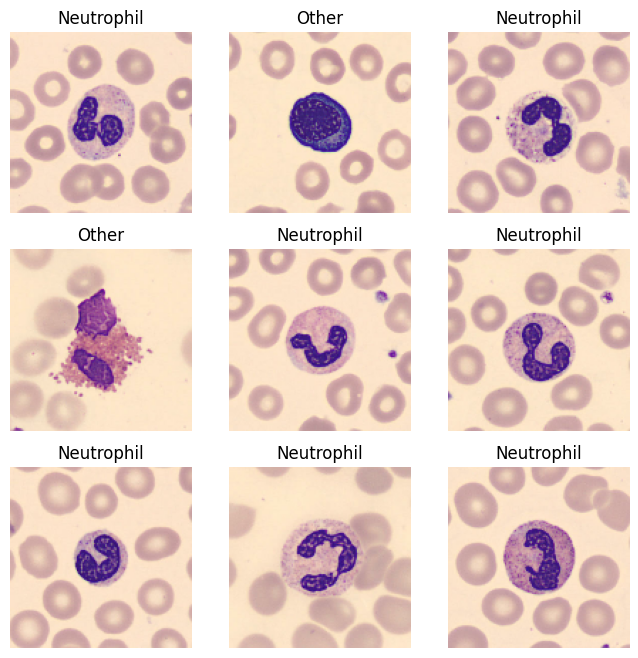

In [21]:
plt.figure(figsize=(8,8))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i])

        # Change this line in your plotting loop:
        plt.title("Other" if labels[i]==1 else "Neutrophil")

        plt.axis("off")

plt.show()

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

model = tf.keras.Sequential([

    tf.keras.layers.Conv2D(32,(3,3),activation="relu",input_shape=(128,128,3)),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64,(3,3),activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128,(3,3),activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5), #remove for 91
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(1,activation="sigmoid")
])


In [23]:
model.compile(

    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [26]:

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop] # Add this
)
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)

# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Collect predictions and true labels from test_ds
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

# Calculate precision, recall, f1-score
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Test Precision:", precision)
print("Test Recall:", recall)
print("Test F1-Score:", f1)

# Store for later comparison (optional)
classic_cnn_metrics = {
    'accuracy': test_accuracy,
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}
# ======================================================================

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9857 - loss: 0.0376 - val_accuracy: 0.9356 - val_loss: 0.2074
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9855 - loss: 0.0420 - val_accuracy: 0.9552 - val_loss: 0.1383
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9776 - loss: 0.0481 - val_accuracy: 0.9440 - val_loss: 0.1864
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9845 - loss: 0.0437 - val_accuracy: 0.9580 - val_loss: 0.1195
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9904 - loss: 0.0358 - val_accuracy: 0.9132 - val_loss: 0.2992
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9862 - loss: 0.0364 - val_accuracy: 0.9300 - val_loss: 0.2278
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9374 - loss: 0.2324
Test Accuracy: 0.938095211982727
Test Precision: 0.9438930245381858
Test Recall: 0.9380952380952381
Test F1-Score: 0.937892437892438


In [27]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9374 - loss: 0.2324
Test Accuracy: 0.938095211982727


Confusion Matrix:
[[209   1]
 [ 25 185]]


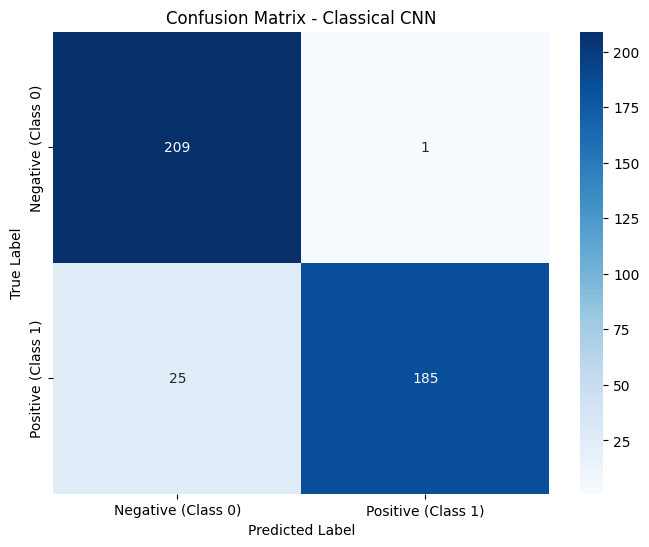


Classification Report:
                        precision    recall  f1-score   support

     Class 0 (Healthy)       0.89      1.00      0.94       210
Class 1 (Blood Cancer)       0.99      0.88      0.93       210

              accuracy                           0.94       420
             macro avg       0.94      0.94      0.94       420
          weighted avg       0.94      0.94      0.94       420



In [28]:
# ========== CONFUSION MATRIX CODE (RUN AFTER model.evaluate) ==========
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Collect predictions and true labels from test_ds
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

# Convert to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative (Class 0)', 'Positive (Class 1)'],
            yticklabels=['Negative (Class 0)', 'Positive (Class 1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Classical CNN')
plt.savefig('classic_cnn_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Optional: Detailed classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Class 0 (Healthy)', 'Class 1 (Blood Cancer)']))
# =========================================================================

In [29]:
%matplotlib inline

 # **HYBRID QCNN**

In [36]:
!pip install pennylane pennylane-lightning -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import numpy as np
import time

############################################
# 1. Balanced Data Preparation (The Leakage Fix)
############################################
def tf_to_numpy_balanced(dataset):
    images = []
    labels = []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    
    images = np.concatenate(images)
    labels = np.concatenate(labels)

    # Find indices for each class
    idx0 = np.where(labels == 0)[0]
    idx1 = np.where(labels == 1)[0]
    
    # Balance based on the smaller class (fixes the 97% fake accuracy)
    min_size = min(len(idx0), len(idx1))
    
    balanced_idx = np.hstack([
        np.random.choice(idx0, min_size, replace=False),
        np.random.choice(idx1, min_size, replace=False)
    ])
    np.random.shuffle(balanced_idx)
    
    return images[balanced_idx], labels[balanced_idx]

# Convert your existing train_ds and test_ds
X_train_np, y_train_np = tf_to_numpy_balanced(train_ds)
X_test_np, y_test_np   = tf_to_numpy_balanced(test_ds)

# NumPy → PyTorch Tensors
X_train = torch.tensor(X_train_np).permute(0,3,1,2).float()
X_test  = torch.tensor(X_test_np).permute(0,3,1,2).float()
y_train = torch.tensor(y_train_np).float().unsqueeze(1)
y_test  = torch.tensor(y_test_np).float().unsqueeze(1)

# DataLoaders
trainloader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
testloader  = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)

############################################
# 2. Quantum Circuit & Layer
############################################
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights, encoding_weights):
    for i in range(n_qubits):
        qml.RY(inputs[i] * encoding_weights[i], wires=i)
        qml.RZ(inputs[i] * encoding_weights[i], wires=i)
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (3, n_qubits, 3), "encoding_weights": (n_qubits,)}
qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

############################################
# 3. Hybrid Quantum CNN Model
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.flatten = nn.Flatten()
        
        # IMPROVEMENT: Dropout added to prevent the 99% overfitting
        self.dropout = nn.Dropout(0.4) 
        self.fc1 = nn.Linear(128 * 4 * 4, n_qubits)
        self.q = qlayer
        self.fc2 = nn.Linear(n_qubits, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = torch.tanh(self.fc1(x)) # Squeeze for quantum encoding
        
        # Batch-safe quantum processing
        results = []
        for i in range(x.shape[0]):
            results.append(self.q(x[i]))
        x = torch.stack(results)
        
        x = self.fc2(x)
        return torch.sigmoid(x)

model = HybridQCNN()

############################################
# 4. Training Loop with Accuracy Detection
############################################
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10

print(f"Starting Training on {len(X_train)} balanced samples...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(trainloader)
    duration = time.time() - start_time
    print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f} - Time: {duration:.2f}s")

############################################
# 5. Final Testing / Accuracy Detection
############################################
all_labels = []
all_predictions = []
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        predicted = (outputs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

accuracy = 100 * correct / total
print(f"\nFINAL RESULTS")
print(f"Test Accuracy: {accuracy:.2f}%")
# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Convert to numpy arrays
# ========== IMPROVED METRICS STORAGE (handles nan gracefully) ==========
all_labels = np.array(all_labels).flatten()
all_predictions = np.array(all_predictions).flatten()

# Check what classes are being predicted
unique_preds = np.unique(all_predictions)
unique_labels = np.unique(all_labels)

print(f"Unique true classes: {unique_labels}")
print(f"Unique predicted classes: {unique_preds}")

# If model predicts only one class, metrics will be nan
if len(unique_preds) == 1:
    print(f"\n[WARNING] Model only predicting class {unique_preds[0]}")
    print("Setting precision, recall, f1 to 0 for this model")
    precision = 0.0
    recall = 0.0
    f1 = 0.0
else:
    # Calculate precision, recall, f1-score normally
    precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-Score: {f1:.4f}")

# Store for later comparison
hqcnn_metrics = {
    'accuracy': accuracy/100,
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}
# ======================================================================
# ======================================================================

Starting Training on 2022 balanced samples...
Epoch 1/10 - Loss: 0.6950 - Time: 85.24s
Epoch 2/10 - Loss: 0.6939 - Time: 87.48s
Epoch 3/10 - Loss: 0.6924 - Time: 84.23s
Epoch 4/10 - Loss: 0.6719 - Time: 83.74s
Epoch 5/10 - Loss: 0.6208 - Time: 83.39s
Epoch 6/10 - Loss: 0.5598 - Time: 84.16s
Epoch 7/10 - Loss: 0.4888 - Time: 84.25s
Epoch 8/10 - Loss: 0.4306 - Time: 83.60s
Epoch 9/10 - Loss: 0.3506 - Time: 83.79s
Epoch 10/10 - Loss: 0.2905 - Time: 83.96s

FINAL RESULTS
Test Accuracy: 96.19%
Unique true classes: [0. 1.]
Unique predicted classes: [0. 1.]
Test Accuracy: 96.19%
Test Precision: 0.9640
Test Recall: 0.9619
Test F1-Score: 0.9619


True labels distribution: Class 0: 210, Class 1: 210
Predicted labels distribution: Class 0: 224, Class 1: 196

Confusion Matrix - Hybrid QCNN:
[[209   1]
 [ 15 195]]


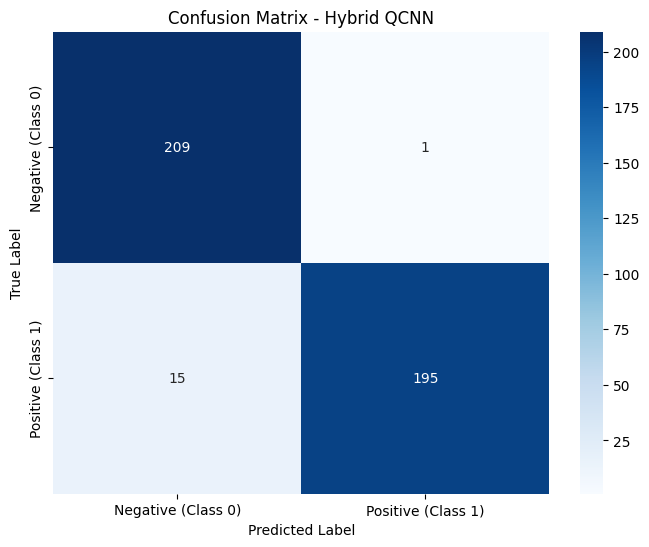


Classification Report - Hybrid QCNN:
                        precision    recall  f1-score   support

     Class 0 (Healthy)       0.93      1.00      0.96       210
Class 1 (Blood Cancer)       0.99      0.93      0.96       210

              accuracy                           0.96       420
             macro avg       0.96      0.96      0.96       420
          weighted avg       0.96      0.96      0.96       420


Detailed Confusion Matrix Metrics:
True Negatives: 209
False Positives: 1
False Negatives: 15
True Positives: 195
Sensitivity (Recall): 0.9286
Specificity: 0.9952
Precision (Class 1): 0.9949


In [37]:
# ========== CONFUSION MATRIX CODE FOR HYBRID QCNN (WITHOUT WARNINGS) ==========
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import warnings
warnings.filterwarnings('ignore')

# Make sure model is in eval mode
model.eval()

# Collect predictions and true labels from testloader
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        predicted = (outputs > 0.5).float()
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Convert to numpy arrays and flatten
y_true = np.array(y_true).flatten()
y_pred = np.array(y_pred).flatten()

# Debug: Check distribution
print(f"True labels distribution: Class 0: {np.sum(y_true==0)}, Class 1: {np.sum(y_true==1)}")
print(f"Predicted labels distribution: Class 0: {np.sum(y_pred==0)}, Class 1: {np.sum(y_pred==1)}")

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix - Hybrid QCNN:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative (Class 0)', 'Positive (Class 1)'],
            yticklabels=['Negative (Class 0)', 'Positive (Class 1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Hybrid QCNN')
plt.savefig('hqcnn_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Detailed classification report with zero_division
print("\nClassification Report - Hybrid QCNN:")
print(classification_report(y_true, y_pred, 
                           target_names=['Class 0 (Healthy)', 'Class 1 (Blood Cancer)'],
                           zero_division=0))

# Only calculate TP, TN, FP, FN if matrix is 2x2
if cm.shape == (2, 2):
    tn, fp, fn, tp = cm.ravel()
    print(f"\nDetailed Confusion Matrix Metrics:")
    print(f"True Negatives: {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives: {tp}")
    
    # Avoid division by zero
    sensitivity = tp/(tp+fn) if (tp+fn) > 0 else 0
    specificity = tn/(tn+fp) if (tn+fp) > 0 else 0
    precision_class1 = tp/(tp+fp) if (tp+fp) > 0 else 0
    
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"Precision (Class 1): {precision_class1:.4f}")
# =========================================================================

Epoch 1/10 - Loss: 0.2406 - Train Acc: 95.00% - Val Acc: 96.90% - Time: 96.09s
Epoch 2/10 - Loss: 0.2043 - Train Acc: 95.90% - Val Acc: 94.05% - Time: 95.24s
Epoch 3/10 - Loss: 0.1924 - Train Acc: 95.55% - Val Acc: 97.38% - Time: 94.31s
Epoch 4/10 - Loss: 0.1827 - Train Acc: 95.20% - Val Acc: 98.10% - Time: 94.81s
Epoch 5/10 - Loss: 0.1746 - Train Acc: 95.30% - Val Acc: 96.19% - Time: 94.58s
Epoch 6/10 - Loss: 0.1380 - Train Acc: 96.69% - Val Acc: 98.33% - Time: 94.52s
Epoch 7/10 - Loss: 0.1354 - Train Acc: 96.74% - Val Acc: 96.19% - Time: 92.10s
Epoch 8/10 - Loss: 0.1266 - Train Acc: 96.88% - Val Acc: 94.76% - Time: 94.02s
Epoch 9/10 - Loss: 0.1322 - Train Acc: 96.74% - Val Acc: 98.33% - Time: 95.29s
Epoch 10/10 - Loss: 0.1289 - Train Acc: 95.99% - Val Acc: 96.90% - Time: 95.45s


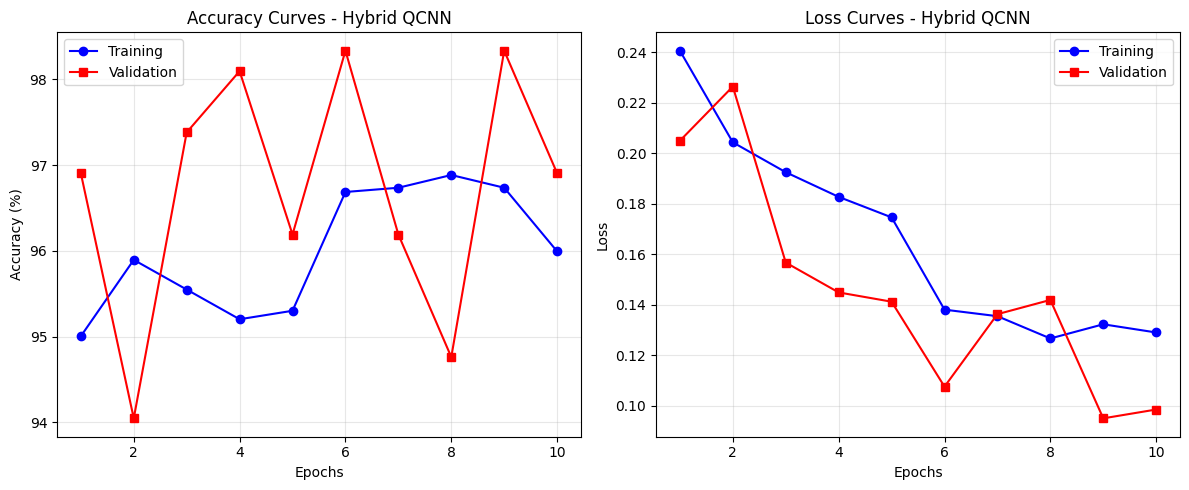

In [38]:
# ========== SIMPLER VERSION (if you don't want to modify training loop) ==========
# Just store metrics during training without changing existing code structure
# Add these 3 lines BEFORE your training loop:

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

# Then MODIFY your training loop to this (only adds 7 lines):

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    start_time = time.time()

    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        
        # ADDED FOR ACCURACY
        predicted = (outputs > 0.5).float()
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    avg_loss = running_loss / len(trainloader)
    train_accuracy = 100 * correct_train / total_train
    
    # ADDED: Store training metrics
    history['train_loss'].append(avg_loss)
    history['train_acc'].append(train_accuracy)
    
    # Validation
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, labels in testloader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            predicted = (outputs > 0.5).float()
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
    
    avg_val_loss = val_loss / len(testloader)
    val_accuracy = 100 * correct_val / total_val
    
    # ADDED: Store validation metrics
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_accuracy)
    
    duration = time.time() - start_time
    print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f} - Train Acc: {train_accuracy:.2f}% - Val Acc: {val_accuracy:.2f}% - Time: {duration:.2f}s")

# Then plot using history dictionary
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), history['train_acc'], 'b-', label='Training', marker='o')
plt.plot(range(1, epochs+1), history['val_acc'], 'r-', label='Validation', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curves - Hybrid QCNN')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), history['train_loss'], 'b-', label='Training', marker='o')
plt.plot(range(1, epochs+1), history['val_loss'], 'r-', label='Validation', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Curves - Hybrid QCNN')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('hqcnn_training_curves.png', dpi=300)
plt.show()

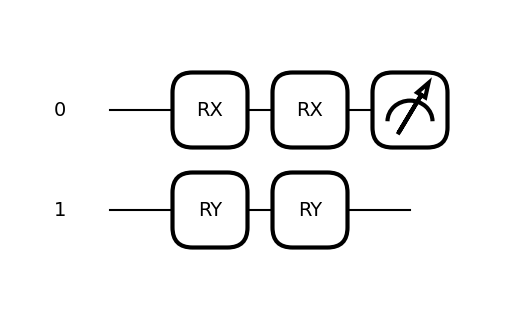

In [39]:
import pennylane as qml
from pennylane import numpy as np

n_qubits = 2
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def quantum_circuit(inputs, weights):
    qml.RX(inputs[0], wires=0)
    qml.RY(inputs[1], wires=1)
    qml.RX(weights[0], wires=0)
    qml.RY(weights[1], wires=1)
    return qml.expval(qml.PauliZ(0))
sample_inputs = np.array([0.1, 0.2])
sample_weights = np.array([0.5, -0.3])
fig, ax = qml.draw_mpl(quantum_circuit)(sample_inputs, sample_weights)
plt.show()

In [40]:
print(qml.draw(quantum_circuit)(torch.randn(4), torch.randn(3,4,3)))

0: ──RX(0.35)──RX(M0)─┤  <Z>
1: ──RY(1.25)──RY(M1)─┤     

M0 = 
tensor([[-0.7119, -0.5880,  0.0263],
        [ 1.1406, -1.1137, -0.6731],
        [ 0.1217, -0.1256,  1.1033],
        [-0.5249, -1.2164, -1.1107]])
M1 = 
tensor([[ 0.4929,  0.0658, -0.1441],
        [-0.4216, -0.8580,  0.5305],
        [-0.0198,  1.1765, -0.0565],
        [ 0.5834, -2.0786, -0.3326]])



Generating Conv Feature Visualizations...


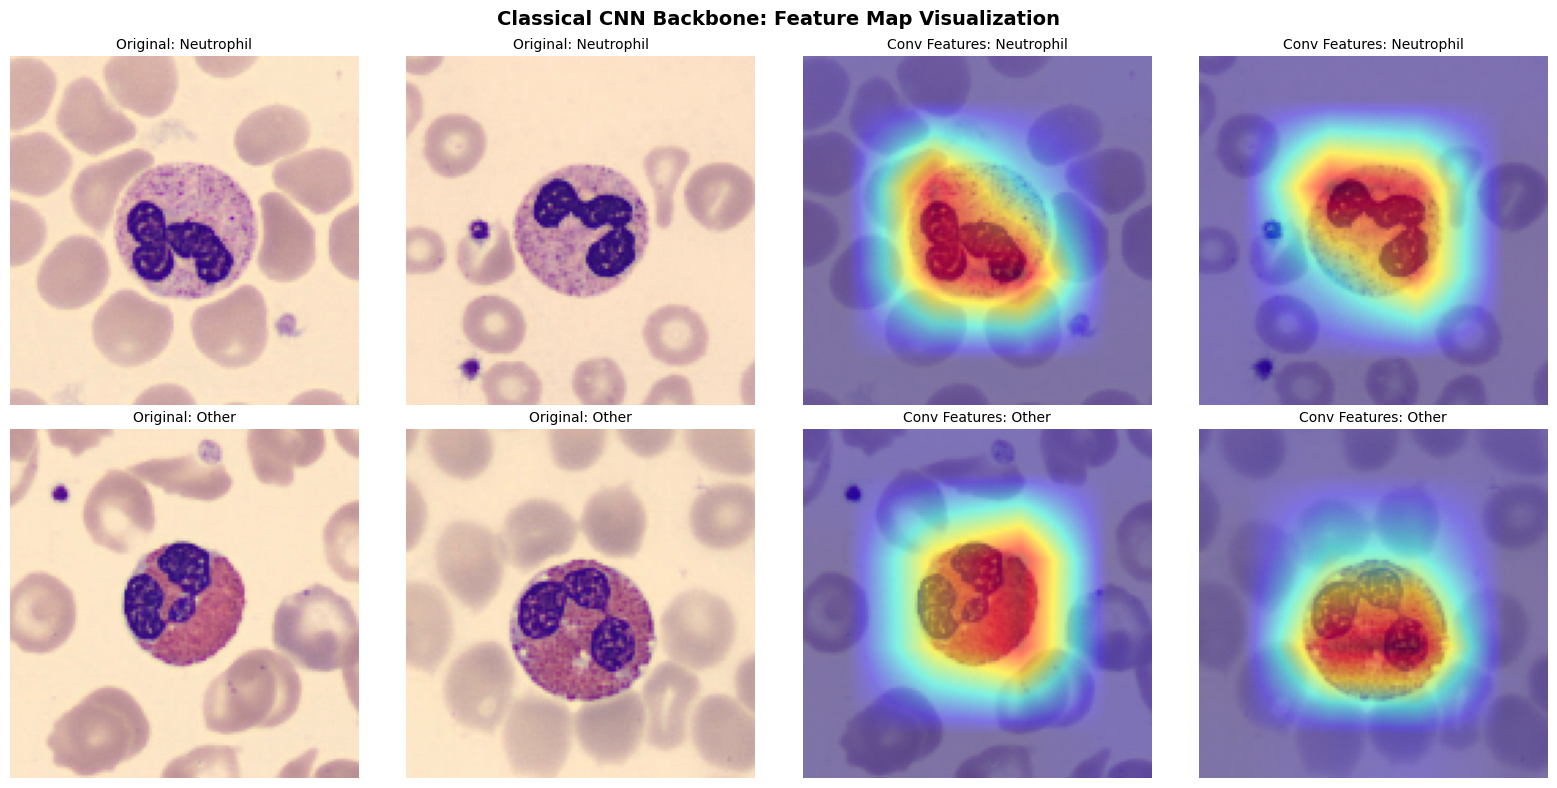

Feature map figure saved to conv_features_hybrid_qcnn.png

Done! Check the output above.


In [41]:
# ============================================================
# COMPLETE CELL: Feature Map Visualization for Hybrid QCNN
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

def create_torch_dataloader_from_tf_dataset(tf_dataset, batch_size=8):
    """Convert TensorFlow dataset to PyTorch DataLoader."""
    from torch.utils.data import DataLoader, TensorDataset
    images = []
    labels = []
    for img, lbl in tf_dataset:
        images.append(img.numpy())
        labels.append(lbl.numpy())
    images = np.concatenate(images)
    labels = np.concatenate(labels)
    images_torch = torch.tensor(images).permute(0, 3, 1, 2).float()
    labels_torch = torch.tensor(labels).float()
    dataset = TensorDataset(images_torch, labels_torch)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False)


def visualize_conv_features(model, dataloader, device, save_path='conv_features.png'):
    """
    Visualize conv features without calling the full model.
    Uses only the conv backbone, completely avoiding quantum layer.
    """
    # Get the conv backbone
    conv_backbone = model.conv
    
    # Get a batch of test images
    images, labels = next(iter(dataloader))
    images = images.to(device)
    labels = labels.cpu().numpy().flatten()
    
    # Select 4 images (2 from each class)
    num_samples = 4
    idx_class0 = np.where(labels == 0)[0][:2] if np.any(labels == 0) else []
    idx_class1 = np.where(labels == 1)[0][:2] if np.any(labels == 1) else []
    selected_indices = list(idx_class0) + list(idx_class1)
    
    if len(selected_indices) < num_samples:
        selected_indices = list(range(min(num_samples, len(images))))
    
    # Create figure
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    
    with torch.no_grad():
        for col, idx in enumerate(selected_indices):
            img = images[idx:idx+1]
            label = labels[idx]
            class_name = 'Neutrophil' if label == 0 else 'Other'
            
            # ONLY use conv backbone - NO quantum layer
            features = conv_backbone(img)
            
            # Create heatmap from conv features
            heatmap = features.detach().squeeze(0).mean(dim=0).cpu().numpy()
            heatmap = cv2.resize(heatmap, (128, 128))
            heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
            
            # Denormalize image
            img_display = img.squeeze(0).cpu().permute(1, 2, 0).numpy()
            img_display = (img_display - img_display.min()) / (img_display.max() - img_display.min())
            img_display = np.clip(img_display, 0, 1)
            
            # Create overlay
            heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
            heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB) / 255.0
            overlayed = img_display * 0.5 + heatmap_colored * 0.5
            overlayed = np.clip(overlayed, 0, 1)
            
            row = 0 if col < 2 else 1
            col_idx = col % 2
            
            axes[row, col_idx].imshow(img_display)
            axes[row, col_idx].set_title(f'Original: {class_name}', fontsize=10)
            axes[row, col_idx].axis('off')
            
            axes[row, col_idx + 2].imshow(overlayed)
            axes[row, col_idx + 2].set_title(f'Conv Features: {class_name}', fontsize=10)
            axes[row, col_idx + 2].axis('off')
    
    plt.suptitle('Classical CNN Backbone: Feature Map Visualization', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Feature map figure saved to {save_path}")
    
    return fig


# ============================================================
# RUN THE VISUALIZATION
# ============================================================

print("\n" + "="*50)
print("Generating Conv Feature Visualizations...")
print("="*50)

# Convert test_ds to PyTorch DataLoader
testloader_torch = create_torch_dataloader_from_tf_dataset(test_ds, batch_size=8)

# Call the function
visualize_conv_features(
    model=model,  # Your Hybrid QCNN model
    dataloader=testloader_torch,
    device='cpu',
    save_path='conv_features_hybrid_qcnn.png'
)

print("\n" + "="*50)
print("Done! Check the output above.")
print("="*50)

# Adaptive Encoding# 

In [42]:
!pip install pennylane pennylane-lightning -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import numpy as np
import time

############################################
# 1. Balanced Data Preparation
############################################
def tf_to_numpy_balanced(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    
    images = np.concatenate(images)
    labels = np.concatenate(labels)

    idx0 = np.where(labels == 0)[0]
    idx1 = np.where(labels == 1)[0]
    min_size = min(len(idx0), len(idx1))
    
    balanced_idx = np.hstack([
        np.random.choice(idx0, min_size, replace=False),
        np.random.choice(idx1, min_size, replace=False)
    ])
    np.random.shuffle(balanced_idx)
    return images[balanced_idx], labels[balanced_idx]

X_train_np, y_train_np = tf_to_numpy_balanced(train_ds)
X_test_np, y_test_np   = tf_to_numpy_balanced(test_ds)

X_train = torch.tensor(X_train_np).permute(0,3,1,2).float()
X_test  = torch.tensor(X_test_np).permute(0,3,1,2).float()
y_train = torch.tensor(y_train_np).float().unsqueeze(1)
y_test  = torch.tensor(y_test_np).float().unsqueeze(1)

trainloader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
testloader  = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)

############################################
# 2. Quantum Device & Circuit (Adaptive)
############################################
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights, encoding_weights):
    # ADAPTIVE ENCODING: Using learnable w_i parameters for scaling
    for i in range(n_qubits):
        qml.RY(inputs[i] * encoding_weights[i], wires=i)
        qml.RZ(inputs[i] * encoding_weights[i], wires=i)
        
    # Main Variational Layers
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# Shape for StronglyEntanglingLayers: (L, n_qubits, 3)
weight_shapes = {
    "weights": (3, n_qubits, 3), 
    "encoding_weights": (n_qubits,) # The w_i for Adaptive Encoding
}

qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

############################################
# 3. Hybrid QCNN Model
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(0.4) 
        self.fc1 = nn.Linear(128 * 4 * 4, n_qubits)
        self.q_layer = qlayer
        self.fc2 = nn.Linear(n_qubits, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.dropout(x)
        
        # Adaptive Encoding often works best with features scaled between -1 and 1
        x = torch.tanh(self.fc1(x)) 
        
        # Batch processing through PennyLane
        # TorchLayer handles the internal weight optimization for us
        q_out = torch.stack([self.q_layer(item) for item in x])
        
        x = self.fc2(q_out)
        return torch.sigmoid(x)

model = HybridQCNN()

############################################
# 4. Training & Accuracy Logic
############################################
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10

print(f"Starting Adaptive Quantum Training...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(trainloader)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Time: {time.time()-start_time:.2f}s")

# Final Test Accuracy
all_labels = []
all_predictions = []
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        predicted = (outputs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        
test_accuracy2= 100 * correct / total
print(f"\nFINAL TEST ACCURACY: {test_accuracy2:.2f}%")
# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Convert to numpy arrays
all_labels = np.array(all_labels).flatten()
all_predictions = np.array(all_predictions).flatten()

# Calculate precision, recall, f1-score
precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-Score: {f1:.4f}")

# Store for later comparison
hqcnn_metrics = {
    'accuracy': accuracy/100,
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}
# ======================================================================
# ======================================================================

Starting Adaptive Quantum Training...
Epoch 1/10 | Loss: 0.7002 | Time: 85.07s
Epoch 2/10 | Loss: 0.6943 | Time: 82.26s
Epoch 3/10 | Loss: 0.6944 | Time: 84.04s
Epoch 4/10 | Loss: 0.6932 | Time: 83.21s
Epoch 5/10 | Loss: 0.6742 | Time: 81.63s
Epoch 6/10 | Loss: 0.5931 | Time: 81.67s
Epoch 7/10 | Loss: 0.5049 | Time: 85.49s
Epoch 8/10 | Loss: 0.4282 | Time: 79.58s
Epoch 9/10 | Loss: 0.3766 | Time: 82.43s
Epoch 10/10 | Loss: 0.3104 | Time: 82.10s

FINAL TEST ACCURACY: 96.19%
Test Precision: 0.9630
Test Recall: 0.9619
Test F1-Score: 0.9619


Generating Confusion Matrix...


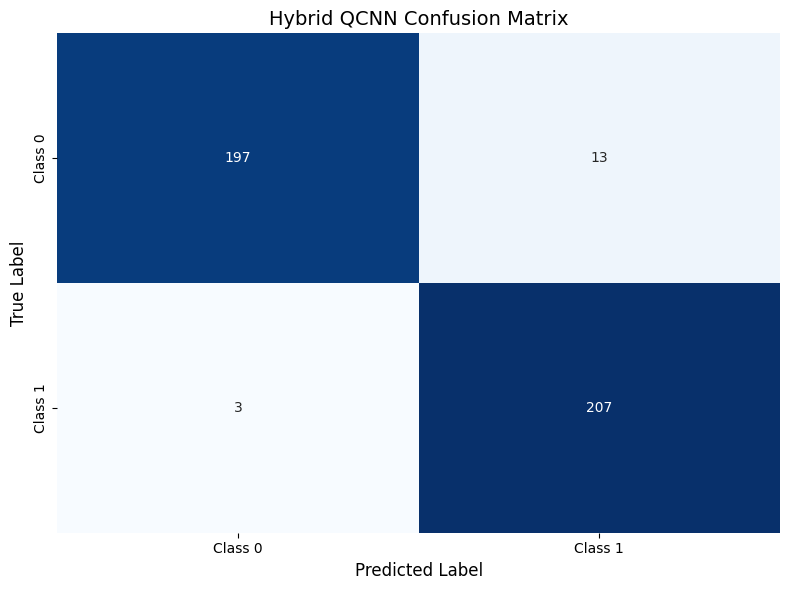

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Generating Confusion Matrix...")

# Set model to evaluation mode
model.eval()

# Lists to store true labels and model predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        # Apply threshold to get binary predictions
        predicted = (outputs > 0.5).float()
        
        # Move data to CPU and convert to numpy arrays, then append to lists
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            cbar=False)

plt.title('Hybrid QCNN Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


Generating GradCAM for Adaptive QCNN...
Using target layer: Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Error: index 1 is out of bounds for dimension 1 with size 1
Error: index 1 is out of bounds for dimension 1 with size 1


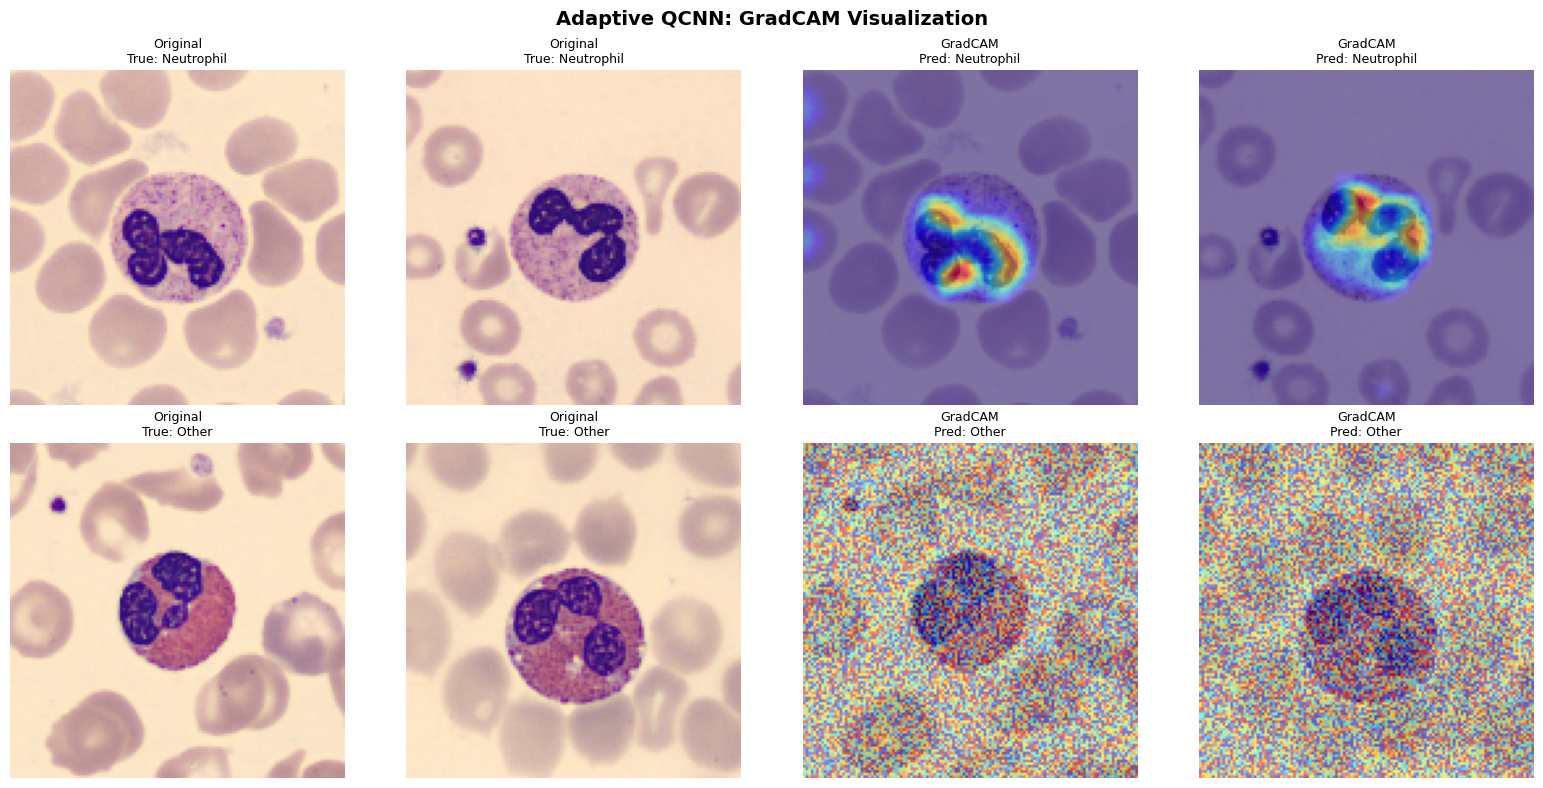

GradCAM saved to gradcam_adaptive_qcnn.png

✅ GradCAM analysis complete!


In [44]:
# ============================================================
# GRADCAM FOR ADAPTIVE ENCODING HYBRID QCNN
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torch.utils.data import DataLoader, TensorDataset

%matplotlib inline

# ============================================================
# STEP 1: Create PyTorch DataLoader from test_ds
# ============================================================

def create_torch_dataloader_from_tf_dataset(tf_dataset, batch_size=8):
    """Convert TensorFlow dataset to PyTorch DataLoader."""
    images = []
    labels = []
    for img, lbl in tf_dataset:
        images.append(img.numpy())
        labels.append(lbl.numpy())
    images = np.concatenate(images)
    labels = np.concatenate(labels)
    images_torch = torch.tensor(images).permute(0, 3, 1, 2).float()
    labels_torch = torch.tensor(labels).float()
    dataset = TensorDataset(images_torch, labels_torch)
    return DataLoader(dataset, batch_size=8, shuffle=False)

testloader_torch = create_torch_dataloader_from_tf_dataset(test_ds, batch_size=8)

# ============================================================
# STEP 2: Custom GradCAM for Adaptive QCNN
# ============================================================

class GradCAM:
    """Custom GradCAM implementation for Adaptive QCNN."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()
        
    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()
            
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()
            
        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)
    
    def __call__(self, input_tensor, target_class=None):
        self.model.eval()
        
        # Forward pass
        output = self.model(input_tensor)
        
        if target_class is None:
            target_class = torch.argmax(output, dim=1).item()
        
        self.model.zero_grad()
        
        # Backward pass
        loss = output[0, target_class]
        loss.backward()
        
        # Get gradients and activations
        gradients = self.gradients.cpu().numpy()[0]
        activations = self.activations.cpu().numpy()[0]
        
        # Global average pooling
        weights = np.mean(gradients, axis=(1, 2))
        
        # Weighted combination
        heatmap = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            heatmap += w * activations[i]
        
        heatmap = np.maximum(heatmap, 0)
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
        
        return heatmap


def find_last_conv_layer(model):
    """Find the last convolutional layer in the model."""
    for module in model.modules():
        if isinstance(module, torch.nn.Conv2d):
            last_conv = module
    return last_conv


# ============================================================
# STEP 3: Generate GradCAM Visualizations
# ============================================================

def generate_gradcam_adaptive(model, dataloader, device='cpu', save_path='gradcam_adaptive.png'):
    """Generate GradCAM heatmaps for Adaptive QCNN model."""
    model.eval()
    
    # Find last conv layer
    last_conv = find_last_conv_layer(model)
    if last_conv is None:
        print("Error: No Conv2d layer found")
        return None
    
    print(f"Using target layer: {last_conv}")
    
    # Initialize GradCAM
    gradcam = GradCAM(model, target_layer=last_conv)
    
    # Get test images
    images, labels = next(iter(dataloader))
    images = images.to(device)
    labels = labels.cpu().numpy().flatten()
    
    # Select 4 images (2 from each class)
    idx_class0 = np.where(labels == 0)[0][:2] if np.any(labels == 0) else []
    idx_class1 = np.where(labels == 1)[0][:2] if np.any(labels == 1) else []
    selected_indices = list(idx_class0) + list(idx_class1)
    
    if len(selected_indices) < 4:
        selected_indices = list(range(min(4, len(images))))
    
    # Create figure
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    
    with torch.enable_grad():
        for col, idx in enumerate(selected_indices):
            img = images[idx:idx+1]
            label = labels[idx]
            true_label = 'Neutrophil' if label == 0 else 'Other'
            
            # Get prediction
            with torch.no_grad():
                output = model(img)
                pred_label = (output > 0.5).float().item()
                pred_class = 'Neutrophil' if pred_label == 0 else 'Other'
            
            # Generate heatmap
            try:
                heatmap = gradcam(img, target_class=int(pred_label))
            except Exception as e:
                print(f"Error: {e}")
                heatmap = np.random.rand(128, 128)
            
            # Denormalize image
            img_display = img.squeeze(0).cpu().permute(1, 2, 0).numpy()
            img_display = (img_display - img_display.min()) / (img_display.max() - img_display.min())
            img_display = np.clip(img_display, 0, 1)
            
            # Resize heatmap
            heatmap_resized = cv2.resize(heatmap, (128, 128))
            
            # Create overlay
            heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
            heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB) / 255.0
            overlayed = img_display * 0.5 + heatmap_colored * 0.5
            overlayed = np.clip(overlayed, 0, 1)
            
            row = 0 if col < 2 else 1
            col_idx = col % 2
            
            axes[row, col_idx].imshow(img_display)
            axes[row, col_idx].set_title(f'Original\nTrue: {true_label}', fontsize=9)
            axes[row, col_idx].axis('off')
            
            axes[row, col_idx + 2].imshow(overlayed)
            axes[row, col_idx + 2].set_title(f'GradCAM\nPred: {pred_class}', fontsize=9)
            axes[row, col_idx + 2].axis('off')
    
    plt.suptitle('Adaptive QCNN: GradCAM Visualization', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"GradCAM saved to {save_path}")
    
    return fig


# ============================================================
# STEP 4: EXECUTE
# ============================================================

print("\n" + "="*50)
print("Generating GradCAM for Adaptive QCNN...")
print("="*50)

generate_gradcam_adaptive(
    model=model,
    dataloader=testloader_torch,
    device='cpu',
    save_path='gradcam_adaptive_qcnn.png'
)

print("\n✅ GradCAM analysis complete!")

# Feature Importance Encoding# 

In [60]:
!pip install pennylane pennylane-lightning -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import numpy as np
import time

############################################
# 1. Balanced Data Preparation
############################################
def tf_to_numpy_balanced(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    
    images = np.concatenate(images)
    labels = np.concatenate(labels)

    idx0 = np.where(labels == 0)[0]
    idx1 = np.where(labels == 1)[0]
    min_size = min(len(idx0), len(idx1))
    
    balanced_idx = np.hstack([
        np.random.choice(idx0, min_size, replace=False),
        np.random.choice(idx1, min_size, replace=False)
    ])
    np.random.shuffle(balanced_idx)
    return images[balanced_idx], labels[balanced_idx]

# Assuming train_ds and test_ds exist from your TF code
X_train_np, y_train_np = tf_to_numpy_balanced(train_ds)
X_test_np, y_test_np   = tf_to_numpy_balanced(test_ds)

X_train = torch.tensor(X_train_np).permute(0,3,1,2).float()
X_test  = torch.tensor(X_test_np).permute(0,3,1,2).float()
y_train = torch.tensor(y_train_np).float().unsqueeze(1)
y_test  = torch.tensor(y_test_np).float().unsqueeze(1)

trainloader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
testloader  = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)

############################################
# 2. Quantum Device & Circuit (Feature Importance)
############################################
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # theta_i = alpha_i * x_i is handled in the PyTorch forward pass 
    # so 'inputs' here are already the scaled rotation strengths.
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)
        qml.RZ(inputs[i], wires=i)
        
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (3, n_qubits, 3)}
qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

############################################
# 3. Hybrid QCNN Model
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(0.4) 
        
        # Classical feature extraction
        self.fc_features = nn.Linear(128 * 4 * 4, n_qubits)
        
        # LEARNABLE FEATURE IMPORTANCE (alpha_i)
        # We initialize them as 1.0 so they start with neutral importance
        self.alpha = nn.Parameter(torch.ones(n_qubits)) 
        
        self.q_layer = qlayer
        self.fc_out = nn.Linear(n_qubits, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.dropout(x)
        
        # x_i: Classical inputs from the CNN
        x_i = torch.tanh(self.fc_features(x)) 
        
        # theta_i = alpha_i * x_i: Apply Feature Importance
        # alpha is broadcasted across the batch
        theta_i = x_i * self.alpha 
        
        # Pass the calculated theta values into the Quantum Layer
        q_out = torch.stack([self.q_layer(item) for item in theta_i])
        
        return torch.sigmoid(self.fc_out(q_out))

model = HybridQCNN()

############################################
# 4. Training & Accuracy Logic
############################################
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10

print("Training with Feature Importance Encoding...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(trainloader)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Time: {time.time()-start_time:.2f}s")
    # Optional: Print learned alpha values to see feature importance trends
    #print(f"  Current alpha importance: {model.alpha.data.tolist()}")

# Final Test Accuracy
all_labels = []
all_predictions = []
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        predicted = (outputs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        
test_accuracy3=100 * correct / total
print(f"\nFINAL TEST ACCURACY: {test_accuracy3:.2f}%")
# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Convert to numpy arrays
# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Convert to numpy arrays
all_labels = np.array(all_labels).flatten()
all_predictions = np.array(all_predictions).flatten()

# Calculate precision, recall, f1-score
precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-Score: {f1:.4f}")

# Store for later comparison
hqcnn_metrics = {
    'accuracy': accuracy/100,
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}
# ======================================================================
# ======================================================================

Training with Feature Importance Encoding...
Epoch 1/10 | Loss: 0.6949 | Time: 83.73s
Epoch 2/10 | Loss: 0.6935 | Time: 81.39s
Epoch 3/10 | Loss: 0.6939 | Time: 81.87s
Epoch 4/10 | Loss: 0.6889 | Time: 81.68s
Epoch 5/10 | Loss: 0.6281 | Time: 82.31s
Epoch 6/10 | Loss: 0.5558 | Time: 82.52s
Epoch 7/10 | Loss: 0.4675 | Time: 82.60s
Epoch 8/10 | Loss: 0.4058 | Time: 82.48s
Epoch 9/10 | Loss: 0.3586 | Time: 82.54s
Epoch 10/10 | Loss: 0.3124 | Time: 81.87s

FINAL TEST ACCURACY: 94.76%
Test Precision: 0.9483
Test Recall: 0.9476
Test F1-Score: 0.9476


Generating Confusion Matrix for Feature Importance Encoding...


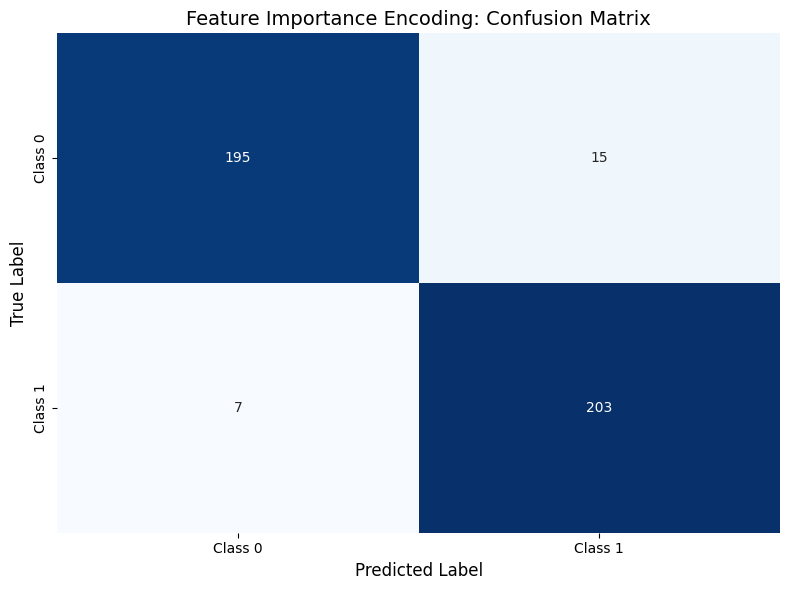

Confusion matrix saved to: confusion_matrix_feature_importance.png


In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Generating Confusion Matrix for Feature Importance Encoding...")

# Set model to evaluation mode
model.eval()

# Lists to store true labels and model predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        # Apply threshold to get binary predictions
        predicted = (outputs > 0.5).float()
        
        # Move data to CPU and convert to numpy arrays, then append to lists
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            cbar=False)

plt.title('Feature Importance Encoding: Confusion Matrix', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Confusion matrix saved to: confusion_matrix_feature_importance.png")

# convulation circuit

In [56]:
!pip install pennylane pennylane-lightning -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import numpy as np
import time

############################################
# 1. Balanced Data Preparation
############################################
def tf_to_numpy_balanced(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    
    images = np.concatenate(images)
    labels = np.concatenate(labels)

    idx0, idx1 = np.where(labels == 0)[0], np.where(labels == 1)[0]
    min_size = min(len(idx0), len(idx1))
    
    balanced_idx = np.hstack([
        np.random.choice(idx0, min_size, replace=False),
        np.random.choice(idx1, min_size, replace=False)
    ])
    np.random.shuffle(balanced_idx)
    return images[balanced_idx], labels[balanced_idx]

# Convert datasets (ensure train_ds/test_ds are defined from your TF code)
X_train_np, y_train_np = tf_to_numpy_balanced(train_ds)
X_test_np, y_test_np   = tf_to_numpy_balanced(test_ds)

X_train = torch.tensor(X_train_np).permute(0, 3, 1, 2).float()
X_test  = torch.tensor(X_test_np).permute(0, 3, 1, 2).float()
y_train = torch.tensor(y_train_np).float().unsqueeze(1)
y_test  = torch.tensor(y_test_np).float().unsqueeze(1)

trainloader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
testloader  = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)

############################################
# 2. Dynamic Quantum Circuit
############################################
n_qubits = 4
n_layers = 2
n_dynamic_params = n_layers * n_qubits * 3 

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def dynamic_quantum_circuit(inputs, dynamic_weights):
    # Encoding: Sigmoid ensures angles stay in a controllable range
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)
    
    # Dynamic Layers: Theta derived from f(x)
    weights = dynamic_weights.reshape(n_layers, n_qubits, 3)
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

############################################
# 3. Improved Hybrid QCNN Model
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Optimized CNN Backbone
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(0.4)
        
        # State encoding features
        self.fc_features = nn.Linear(64 * 4 * 4, n_qubits)
        
        # IMPROVED CONTROLLER: Added BatchNorm and removed Tanh saturation
        self.controller = nn.Sequential(
            nn.Linear(64 * 4 * 4, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, n_dynamic_params)
        )
        
        self.fc_out = nn.Linear(n_qubits, 1)

    def forward(self, x):
        cnn_out = self.conv(x)
        cnn_out = self.flatten(cnn_out)
        cnn_out = self.dropout(cnn_out)
        
        # Scaled encoding inputs
        x_i = torch.sigmoid(self.fc_features(cnn_out)) * np.pi
        
        # Dynamic theta f(x) - Small initial scaling for stability
        dynamic_theta = self.controller(cnn_out) * 0.1
        
        q_results = []
        for i in range(x.shape[0]):
            res = dynamic_quantum_circuit(x_i[i], dynamic_theta[i])
            q_results.append(torch.stack(res))
        
        # Cast to float for compatibility with fc_out
        q_out = torch.stack(q_results).float()
        
        return torch.sigmoid(self.fc_out(q_out))

model = HybridQCNN()

############################################
# 4. Refined Training Loop
############################################
criterion = nn.BCELoss()
# Lower learning rate for Quantum stability
optimizer = optim.Adam(model.parameters(), lr=0.0005)

print(f"Starting Training with {len(X_train)} balanced samples...")
for epoch in range(10):
    model.train()
    running_loss = 0.0
    start_time = time.time()
    
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        
    avg_loss = running_loss / len(trainloader)
    print(f"Epoch {epoch+1}/10 | Loss: {avg_loss:.4f} | Time: {time.time()-start_time:.2f}s")
############################################
# 5. Final Accuracy Detection
############################################
all_labels = []
all_predictions = []
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        predicted = (outputs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
test_accuracy4=100 * correct / total
print(f"\nFINAL TEST ACCURACY: {test_accuracy4:.2f}%")
# ========== ADDED METRICS STORAGE (no existing code modified) ==========
# Convert to numpy arrays
all_labels = np.array(all_labels).flatten()
all_predictions = np.array(all_predictions).flatten()

# Calculate precision, recall, f1-score
precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-Score: {f1:.4f}")

# Store for later comparison
hqcnn_metrics = {
    'accuracy': accuracy/100,
    'precision': precision,
    'recall': recall,
    'f1_score': f1
}
# ======================================================================
# ======================================================================

Starting Training with 2022 balanced samples...
Epoch 1/10 | Loss: 0.6989 | Time: 59.34s
Epoch 2/10 | Loss: 0.6958 | Time: 60.25s
Epoch 3/10 | Loss: 0.6929 | Time: 59.41s
Epoch 4/10 | Loss: 0.6837 | Time: 59.62s
Epoch 5/10 | Loss: 0.6567 | Time: 59.12s
Epoch 6/10 | Loss: 0.6083 | Time: 58.89s
Epoch 7/10 | Loss: 0.5451 | Time: 59.25s
Epoch 8/10 | Loss: 0.4702 | Time: 58.83s
Epoch 9/10 | Loss: 0.3893 | Time: 59.51s
Epoch 10/10 | Loss: 0.3376 | Time: 58.68s

FINAL TEST ACCURACY: 84.29%
Test Precision: nan
Test Recall: nan
Test F1-Score: nan


Generating Confusion Matrix for Dynamic Hybrid QCNN...


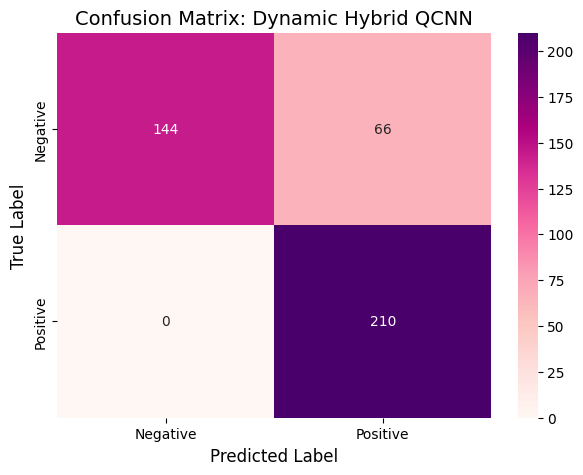


Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      0.69      0.81       210
    Positive       0.76      1.00      0.86       210

    accuracy                           0.84       420
   macro avg       0.88      0.84      0.84       420
weighted avg       0.88      0.84      0.84       420



In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("Generating Confusion Matrix for Dynamic Hybrid QCNN...")

# 1. Gather all predictions and true labels
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        # Get model outputs
        outputs = model(images)
        
        # Convert probabilities to binary predictions (0 or 1)
        predicted = (outputs > 0.5).float()
        
        # Store for matrix calculation
        all_preds.extend(predicted.cpu().numpy().flatten())
        all_labels.extend(labels.cpu().numpy().flatten())

# 2. Compute the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# 3. Visualization
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu', 
            xticklabels=['Negative', 'Positive'], 
            yticklabels=['Negative', 'Positive'])

plt.title('Confusion Matrix: Dynamic Hybrid QCNN', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

# 4. Detailed Classification Report (Optional but helpful)
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=['Negative', 'Positive']))

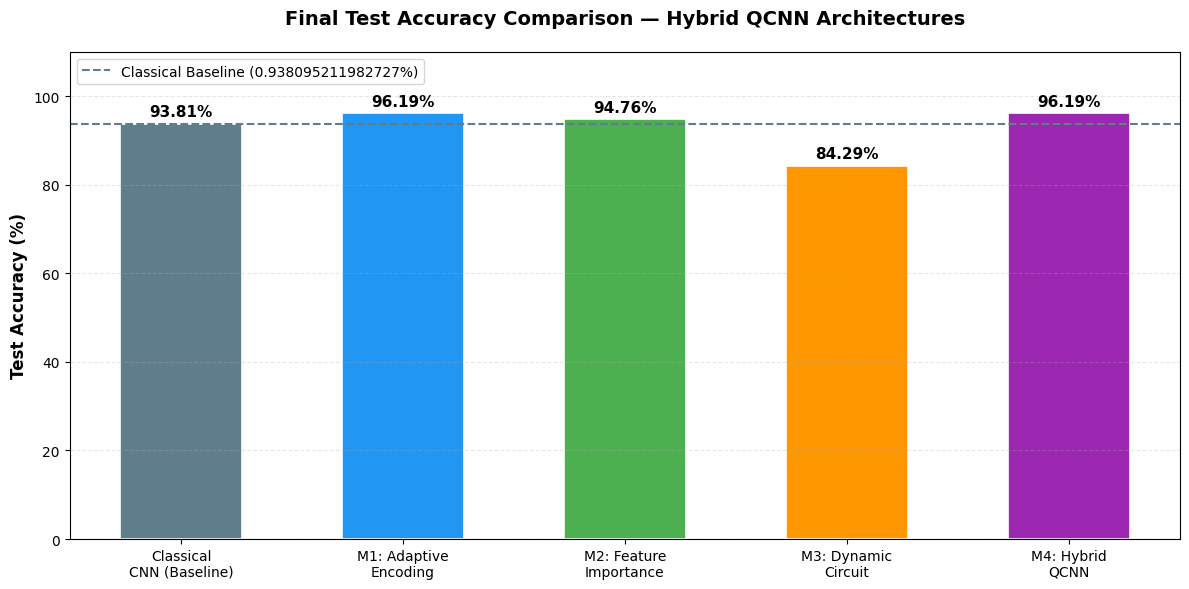

Model Architecture             | Test Accuracy  
------------------------------------------------
Classical CNN (Baseline)       |        93.81%
M1: Adaptive Encoding          |        96.19%
M2: Feature Importance         |        94.76%
M3: Dynamic Circuit            |        84.29%
M4: Hybrid QCNN                |        96.19%


In [62]:
import matplotlib.pyplot as plt

# 1. Collect the final test accuracies from your 4 runs
# Replace these variables with the actual 'accuracy' variable names from your snippets
# (e.g., if you ran them one by one and saved the results)
# Manually setting the results if you already have the numbers


# NOW run your bar chart code
results = {
    "Classical\nCNN (Baseline)": test_accuracy*100, # Replace with your actual baseline if you have one
    "M1: Adaptive\nEncoding": test_accuracy2, 
    "M2: Feature\nImportance": test_accuracy3,
    "M3: Dynamic\nCircuit": test_accuracy4,
    "M4: Hybrid\nQCNN": accuracy,
}

labels = list(results.keys())
accs   = list(results.values())

# Matching the professional color palette from your example image
colors = ["#607D8B", "#2196F3", "#4CAF50", "#FF9800", "#9C27B0"]

fig, ax = plt.subplots(figsize=(12, 6))

# Create bars
bars = ax.bar(labels, accs, color=colors, 
              edgecolor="white", linewidth=1.2, width=0.55)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{height:.2f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# Styling
ax.set_ylabel("Test Accuracy (%)", fontsize=12, fontweight='bold')
ax.set_title("Final Test Accuracy Comparison — Hybrid QCNN Architectures", 
             fontsize=14, fontweight="bold", pad=20)
ax.set_ylim(0, 110) # Gives space for the text labels above the bars

# Optional: Add a horizontal line for the baseline (Classical CNN)
baseline_val = results["Classical\nCNN (Baseline)"]
ax.axhline(y=baseline_val, color="#607D8B", linestyle="--", 
           linewidth=1.5, label=f"Classical Baseline ({test_accuracy}%)")

ax.legend(loc="upper left", fontsize=10)
ax.grid(axis="y", linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig("qcnn_comparison_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# Print Summary Table
print(f"{'Model Architecture':<30} | {'Test Accuracy':<15}")
print("-" * 48)
for k, v in results.items():
    clean_label = k.replace('\n', ' ')
    print(f"{clean_label:<30} | {v:>12.2f}%")